# Напишите заголовок проекта здесь

- Автор:  Лагода Максим Вячеславович
- Дата: 27.01..2026

### Цели и задачи проекта

Цель исследования — изучить распределение заведений по категориям и районам, выявить особенности сетевых и несетевых заведений, а также определить факторы, связанные с рейтингами и ценовой политикой заведений, и сформулировать рекомендации для заказчика.

### Описание данных

Файл /datasets/rest_info.csv содержит информацию о заведениях общественного питания:
- name — название заведения;
- address — адрес заведения;
- district — административный район, в котором находится заведение, например Центральный административный округ;
- category — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- hours — информация о днях и часах работы;
- rating — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- chain — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
    - 0 — заведение не является сетевым;
    - 1 — заведение является сетевым.
- seats — количество посадочных мест.

Файл /datasets/rest_price.csv содержит информацию о среднем чеке в заведениях общественного питания:
- price — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- avg_bill — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:
    - «Средний счёт: 1000–1500 ₽»;
    - «Цена чашки капучино: 130–220 ₽»;
    - «Цена бокала пива: 400–600 ₽».
    - и так далее;
- middle_avg_bill — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- middle_coffee_cup — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

### Содержимое проекта

- Загрузка данных и знакомство с ними
    - Импорт библиотек, загрузка датасетов, первичное изучение структуры данных и общей информации о признаках.

- Предобработка данных
    - Анализ и обработка пропущенных значений, проверка корректности типов данных, работа с текстовыми признаками, создание новых аналитических столбцов.

- Исследовательский анализ данных
    - Анализ распределения заведений по категориям и административным районам Москвы, изучение сетевых и несетевых заведений, исследование рейтингов, количества посадочных мест и ценовых показателей, анализ взаимосвязей между признаками.

- Формирование итоговых выводов и рекомендаций
    - Обобщение результатов исследования и формулирование практических рекомендаций для заказчика на основе проведённого анализа.

## 1. Загрузка данных и знакомство с ними

- Загрузите данные о заведениях общественного питания Москвы. Путь к файлам: `/datasets/rest_info.csv` и `/datasets/rest_price.csv`.

In [1]:
!pip install phik

     |████████████████████████████████| 677 kB 2.0 MB/s eta 0:00:01


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from phik import phik_matrix

In [3]:
rest_info = pd.read_csv('/datasets/rest_info.csv')
rest_price = pd.read_csv('/datasets/rest_price.csv')

- Познакомьтесь с данными и изучите общую информацию о них.

In [4]:
rest_info.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
rest_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [6]:
rest_price.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
rest_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


---

### Промежуточный вывод

Сделайте промежуточный вывод о полученных данных: данные какого объёма вам предоставили, соответствуют ли данные описанию, встречаются ли в них пропуски, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

Были загружены два датасета rest_info.csv и rest_price.csv. Данные соответствуют описанию. Названия столбцов нормализованы. Обьем информации 591.2+ KB и 158.6+ KB соответсвенно. Встречено большое количество пропусков в price, avg_bill, middle_avg_bill, middle_coffee_cup, seats что может быть связано как с отсутсвием заполнения данных так и с неправильностью формирования(касательно middle_avg_bill и middle_coffee_cup) а так же незначительное отсутствие данных в hours. Так же для экономии памяти преобразуем тип переменной chain.

### Подготовка единого датафрейма

- Объедините данные двух датасетов в один, с которым вы и продолжите работу.

In [8]:
data = rest_info.merge(rest_price, on="id", how='left')

In [9]:
data.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


## 2. Предобработка данных

Подготовьте данные к исследовательскому анализу:

- Изучите корректность типов данных и при необходимости проведите их преобразование.

In [11]:
data.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                  int64
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

In [12]:
data['chain'] = data['chain'].astype('bool')

- Изучите пропущенные значения в данных: посчитайте их количество в каждом столбце датафрейме, изучите данные с пропущенными значениями и предположите гипотезы их появления. Проведите обработку пропущенных значений: вы можете заменить пропуски на определённое значение, удалить строки с пропусками или оставить их как есть.

In [13]:
missing_data = pd.DataFrame({
    'Пропущено абсолютно': data.isna().sum(),
    'Доля пропусков, %': (data.isna().mean() * 100).round(2)
}).sort_values(by='Доля пропусков, %', ascending=False)

display(missing_data)

,Пропущено абсолютно,"Доля пропусков, %"
middle_coffee_cup,7871,93.64
middle_avg_bill,5257,62.54
price,5091,60.56
avg_bill,4590,54.60
seats,3611,42.96
hours,536,6.38
id,0,0.00
name,0,0.00
category,0,0.00
address,0,0.00


- Проверьте данные на явные и неявные дубликаты, например поля с названием и адресом заведения. Для оптимизации проверки нормализуйте данные в текстовых столбцах, например с названием заведения.

In [14]:
data.duplicated().sum()

0

In [15]:
data['name_norm'] = data['name'].str.lower().str.strip()
data['address_norm'] = data['address'].str.lower().str.strip()

data.duplicated(subset=['name_norm', 'address_norm']).sum()

4

In [16]:
data = data.drop_duplicates(subset=['name_norm', 'address_norm'])

- Для дальнейшей работы создайте столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [17]:
hours_unique = data['hours'].dropna().str.lower().unique()


hours_unique

array(['ежедневно, 10:00–22:00',
       'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00',
       'ежедневно, 09:00–22:00', ...,
       'пн-пт 08:30–21:30; сб,вс 09:00–21:30',
       'пн-чт 13:00–22:00; пт,сб 13:00–22:30; вс 13:00–22:00',
       'пн-сб 10:30–21:30'], dtype=object)

In [18]:
data.loc[:, 'is_24_7'] = data['hours'].str.lower().isin([
    'ежедневно, круглосуточно',
    'ежедневно, 00:00–24:00'
])

In [19]:
data.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,name_norm,address_norm,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,False,NaN,NaN,NaN,NaN,NaN,wowфли,"москва, улица дыбенко, 7/1",False
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,False,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,четыре комнаты,"москва, улица дыбенко, 36, корп. 1",False
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN,хазри,"москва, клязьминская улица, 15",False
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,False,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,dormouse coffee shop,"москва, улица маршала федоренко, 12",False
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,True,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN,иль марко,"москва, правобережная улица, 1б",False


---

### Промежуточный вывод

После предобработки данных напишите промежуточный вывод о проведённой работе. Отразите количество или долю отфильтрованных данных, если вы что-то удаляли.

Было удалено 4 неявных дубликата. avg_bill, middle_avg_bill, middle_coffee_cup, price были оставлены без изменений в связи с тем что удаление такого значительного обьема данных скажется на дальнейшем иследовании, а заполнение не возможно в связи с не явными критериями заполнения avg_bill и price, а так же с прямой зависимостью middle_avg_bill, middle_coffee_cup от данных avg_bill однако было перепроверено их заполнение и обнаружено расхождения условия заполнения из описания данных и фактического.

## 3. Исследовательский анализ данных
Проведите исследовательский анализ исходных данных.

При исследовании данных используйте визуализации. Проверьте, что для каждого случая подобран оптимальный тип визуализации с корректным оформлением. У графика должен быть заголовок, понятные подписи по осям, при необходимости легенда, а его размер является оптимальным для изучения.

После исследования каждого пункта оставляйте небольшой комментарий с выводом или обсуждением результата. В конце шага обобщите результаты, выделив, по вашему мнению, самые важные.

---

### Задача 1

Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

In [20]:
data['category'].value_counts()

кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

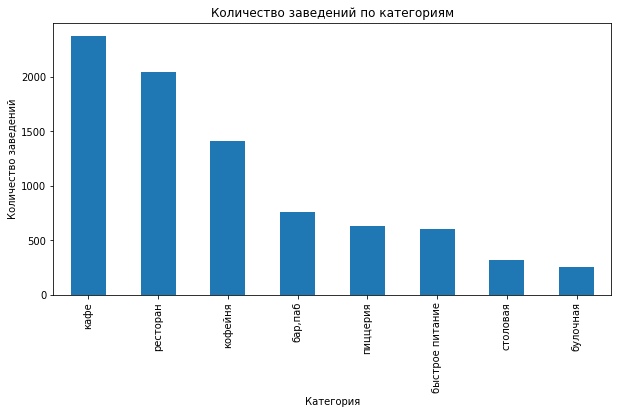

In [21]:
plt.figure(figsize=(10,5))
data['category'].value_counts().plot(kind='bar')
plt.title('Количество заведений по категориям')
plt.xlabel('Категория')
plt.ylabel('Количество заведений')
plt.show()

Вывод: Наиболее широко представлены кафе и рестораны. Это указывает на высокую конкуренцию в данных сегментах рынка общественного питания.

---

### Задача 2

Какие административные районы Москвы присутствуют в данных? Исследуйте распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.

In [22]:
data['district'].value_counts()

Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

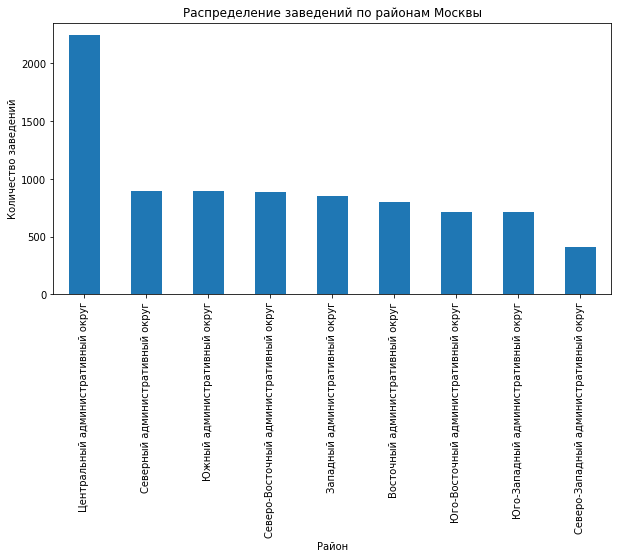

In [23]:
plt.figure(figsize=(10,5))
data['district'].value_counts().plot(kind='bar')
plt.title('Распределение заведений по районам Москвы')
plt.xlabel('Район')
plt.ylabel('Количество заведений')
plt.show()

In [24]:
data_cao = data[data['district'] == 'Центральный административный округ']

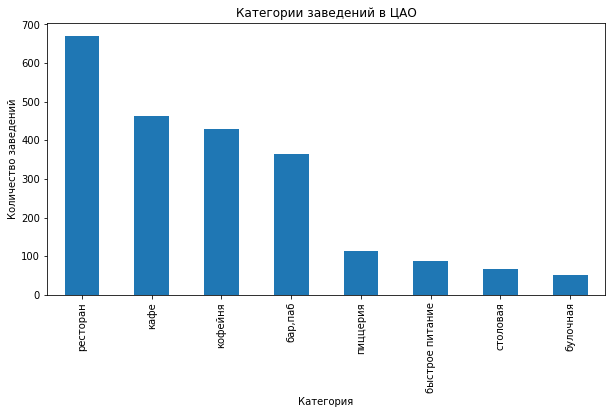

In [25]:
plt.figure(figsize=(10,5))
data_cao['category'].value_counts().plot(kind='bar')
plt.title('Категории заведений в ЦАО')
plt.xlabel('Категория')
plt.ylabel('Количество заведений')
plt.show()

Вывод: Центральный административный округ лидирует по количеству заведений. В ЦАО преобладают кафе и рестораны, что объясняется высокой проходимостью и туристической привлекательностью района.

---

### Задача 3

Изучите соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуйте данные, ответьте на вопросы и постройте необходимые визуализации.

In [26]:
data['chain'].value_counts(normalize=True)

False    0.618781
True     0.381219
Name: chain, dtype: float64

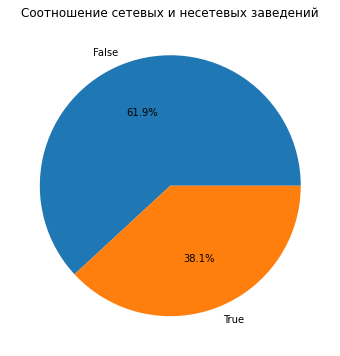

In [27]:
plt.figure(figsize=(6,6))
data['chain'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Соотношение сетевых и несетевых заведений')
plt.ylabel('')
plt.show()

In [28]:
data.groupby('category')['chain'].mean().sort_values(ascending=False)

category
булочная           0.613281
пиццерия           0.521327
кофейня            0.509554
быстрое питание    0.384743
ресторан           0.357003
кафе               0.327862
столовая           0.279365
бар,паб            0.219895
Name: chain, dtype: float64

Вывод: В данных преобладают несетевые заведения. Наибольшая доля сетевых заведений характерна для булочных, пиццерий и кофеен.

---

### Задача 4

Исследуйте количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведите для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводите подходящими визуализациями.


In [29]:
data['seats'].describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

In [30]:
category_order_seats = (
    data.groupby('category')['seats']
    .median()
    .sort_values(ascending=False)
    .index
)

category_order_seats

Index(['ресторан', 'бар,паб', 'кофейня', 'столовая', 'быстрое питание', 'кафе',
       'пиццерия', 'булочная'],
      dtype='object', name='category')

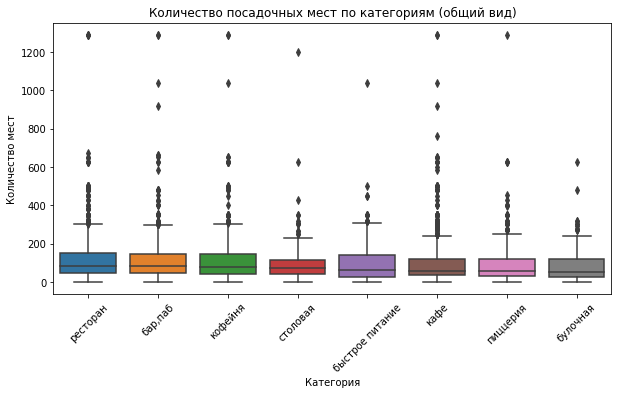

In [31]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    x='category',
    y='seats',
    data=data,
    order=category_order_seats
)
plt.xticks(rotation=45)
plt.title('Количество посадочных мест по категориям (общий вид)')
plt.xlabel('Категория')
plt.ylabel('Количество мест')
plt.show()

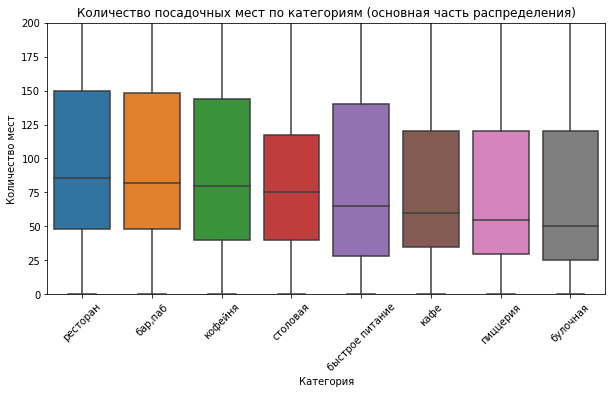

In [32]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    x='category',
    y='seats',
    data=data,
    order=category_order_seats
)
plt.ylim(0, 200)
plt.xticks(rotation=45)
plt.title('Количество посадочных мест по категориям (основная часть распределения)')
plt.xlabel('Категория')
plt.ylabel('Количество мест')
plt.show()

Вывод: Наибольшее количество посадочных мест характерно для ресторанов. В данных присутствуют выбросы, которые могут быть связаны с крупными заведениями или фуд-кортами.

---

### Задача 5

Исследуйте рейтинг заведений. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

In [33]:
category_order = (
    data.groupby('category')['rating']
    .mean()
    .sort_values(ascending=False)
    .index
)

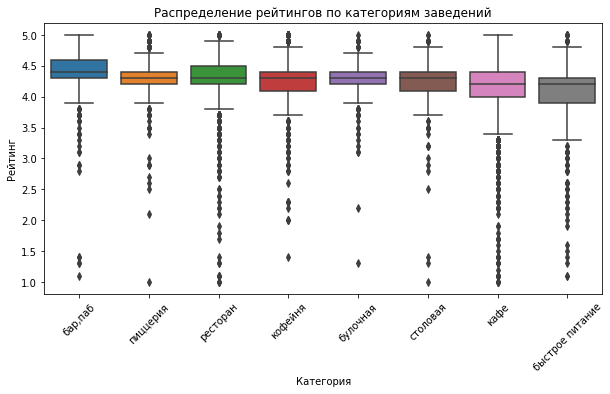

In [34]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    x='category',
    y='rating',
    data=data,
    order=category_order
)
plt.title('Распределение рейтингов по категориям заведений')
plt.xlabel('Категория')
plt.ylabel('Рейтинг')
plt.xticks(rotation=45)
plt.show()

Вывод: Средние рейтинги по категориям отличаются незначительно, однако рестораны и кофейни демонстрируют более высокие оценки.

---

### Задача 6

Изучите, с какими данными показывают самую сильную корреляцию рейтинги заведений? Постройте и визуализируйте матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберите самую сильную связь и проверьте её.

In [35]:
phik_data = data[[
    'rating',
    'category',
    'district',
    'chain',
    'seats',
    'price',
    'is_24_7'
]].copy()

In [36]:
phik_corr = phik_data.phik_matrix()
phik_corr

interval columns not set, guessing: ['rating', 'seats']


,rating,category,district,chain,seats,price,is_24_7
rating,1.000000,0.189716,0.200761,0.107833,0.000000,0.220295,0.150365
category,0.189716,1.000000,0.174584,0.266000,0.048923,0.566933,0.244815
district,0.200761,0.174584,1.000000,0.064473,0.352440,0.202787,0.076357
chain,0.107833,0.266000,0.064473,1.000000,0.056523,0.218211,0.043488
seats,0.000000,0.048923,0.352440,0.056523,1.000000,0.088146,0.043193
price,0.220295,0.566933,0.202787,0.218211,0.088146,1.000000,0.084183
is_24_7,0.150365,0.244815,0.076357,0.043488,0.043193,0.084183,1.000000


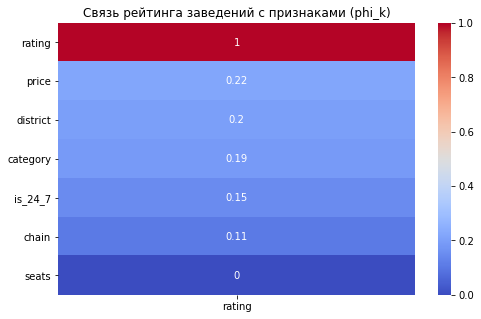

In [37]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    phik_corr[['rating']].sort_values(by='rating', ascending=False),
    annot=True,
    cmap='coolwarm'
)
plt.title('Связь рейтинга заведений с признаками (phi_k)')
plt.show()

In [38]:
price_rating = (
    data
    .groupby('price')['rating']
    .mean()
    .sort_values()
)

price_rating

price
низкие           4.173077
средние          4.297874
выше среднего    4.386348
высокие          4.436611
Name: rating, dtype: float64

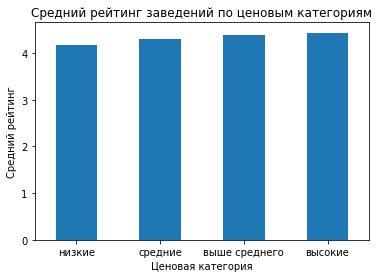

In [39]:
plt.figure(figsize=(6, 4))
price_rating.plot(kind='bar')
plt.title('Средний рейтинг заведений по ценовым категориям')
plt.xlabel('Ценовая категория')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=0)
plt.show()

Вывод: Существенной корреляции рейтинга с числовыми признаками не выявлено. Наиболее заметные различия в рейтингах наблюдаются с ценами в заведении (чем выше ценовая категория заведения тем выше средний рейтинг).

---

### Задача 7

Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитайте значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводите подходящими визуализациями.

In [40]:
top_chains = (
data[data['chain'] == 1]
.groupby('name')
.agg(count=('name', 'count'), avg_rating=('rating', 'mean'))
.sort_values(by='count', ascending=False)
.head(15)
)

In [41]:
top_chains

,count,avg_rating
name,,
Шоколадница,120,4.177500
Домино'с Пицца,76,4.169737
Додо Пицца,74,4.286486
One Price Coffee,71,4.064789
Яндекс Лавка,69,3.872464
Cofix,65,4.075385
Prime,50,4.116000
Хинкальная,44,4.322727
КОФЕПОРТ,42,4.147619


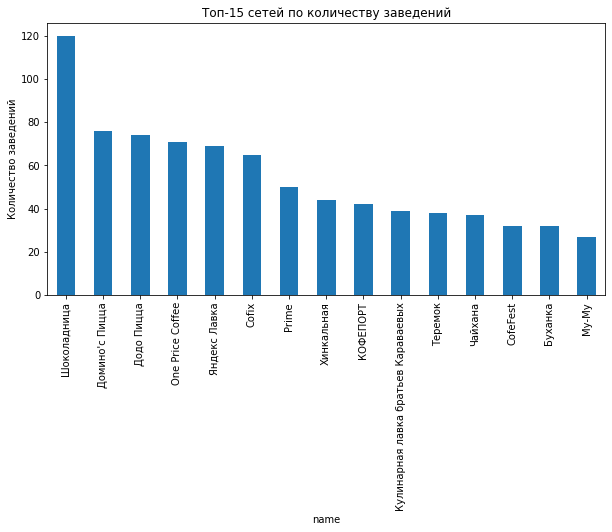

In [42]:
top_chains['count'].plot(kind='bar', figsize=(10,5))
plt.title('Топ-15 сетей по количеству заведений')
plt.ylabel('Количество заведений')
plt.show()

Вывод: Наиболее популярные сети относятся преимущественно к категориям кофеен и предприятий быстрого питания.

---

### Задача 8

Изучите вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируйте цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводите подходящими визуализациями.


In [43]:
district_order = (
    data
    .groupby('district')['middle_avg_bill']
    .mean()
    .sort_values()
    .index
)

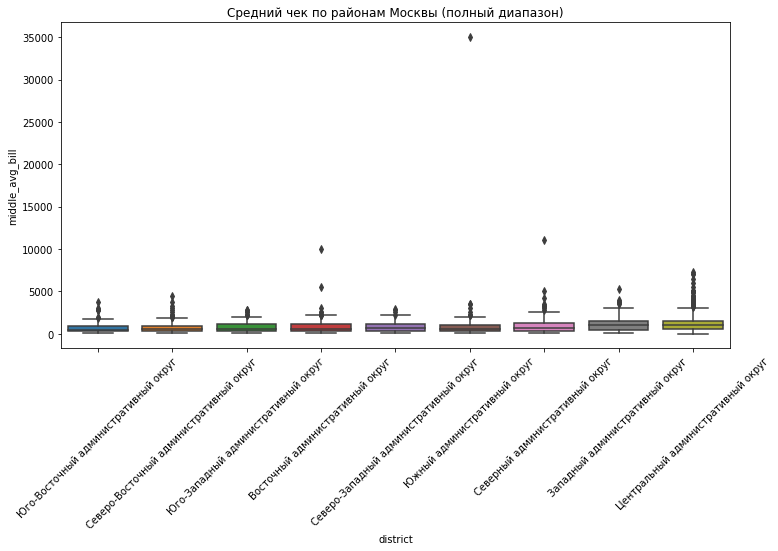

In [44]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    x='district',
    y='middle_avg_bill',
    data=data,
    order=district_order
)
plt.xticks(rotation=45)
plt.title('Средний чек по районам Москвы (полный диапазон)')
plt.show()

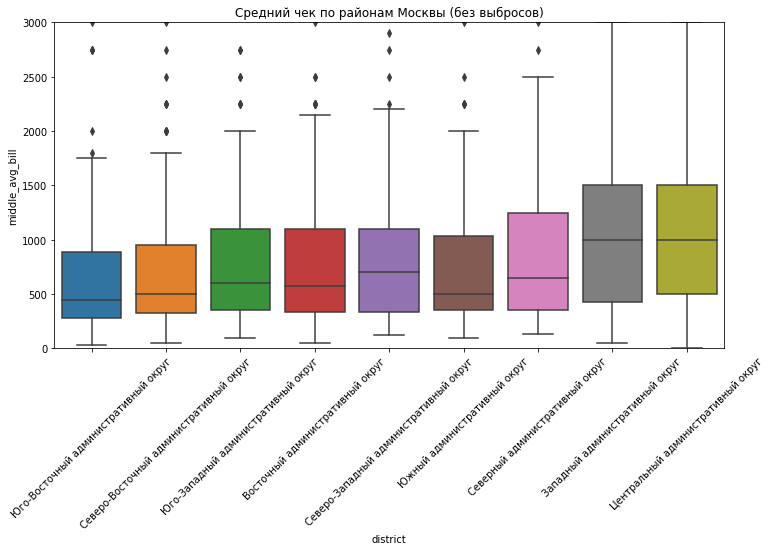

In [45]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    x='district',
    y='middle_avg_bill',
    data=data,
    order=district_order
)
plt.ylim(0, 3000)
plt.xticks(rotation=45)
plt.title('Средний чек по районам Москвы (без выбросов)')
plt.show()

Вывод: В Центральном административном округе наблюдается более высокий средний чек по сравнению с удалёнными районами, что указывает на влияние расположения на ценовую политику заведений.

---

### Промежуточный вывод

Обобщите полученные результаты, выделив, по вашему мнению, самые важные.

В ходе анализа выявлены различия между форматами заведений, районами и ценовыми категориями. Категория заведения и его расположение оказывают наибольшее влияние на рейтинг и средний чек.

## 4. Итоговый вывод и рекомендации

По результатам проведённого исследовательского анализа данных сформулируйте итоговый вывод и рекомендации для заказчика. Старайтесь акцентировать внимание на ключевых моментах исследования.

При составлении вывода придерживайтесь такой структуры:

1. Общий обзор проделанной работы.
2. Ответы на исследовательские вопросы, или главные выводы.
3. Рекомендации на основе анализа данных.

- 1. Общий обзор проделанной работы

    - В рамках проекта был проведён исследовательский анализ данных заведений общественного питания Москвы. Данные были загружены, объединены и предобработаны, включая анализ пропусков, проверку корректности признаков и формирование новых аналитических переменных. Далее был выполнен исследовательский анализ распределений заведений, рейтингов и ценовых показателей.

- 2. Основные выводы исследования

    - Наибольшее количество заведений общественного питания сосредоточено в Центральном административном округе Москвы.
    - Наиболее распространённые категории заведений — кафе и рестораны.
    - В целом в данных преобладают несетевые заведения, однако доля сетевых выше среди кофеен и заведений быстрого питания.
    - Количество посадочных мест существенно различается в зависимости от категории заведения; наибольшие значения характерны для ресторанов.
    - Существенной корреляции между рейтингами заведений и числовыми признаками не выявлено; наибольшие различия в рейтингах связаны с категорией заведения.
    - Средний чек в заведениях Центрального административного округа выше, чем в других районах Москвы.

- 3. Рекомендации заказчику

    - При открытии нового заведения учитывать формат и категорию как ключевые факторы восприятия.
    - Рассматривать районы за пределами ЦАО для снижения затрат при сохранении конкурентного уровня рейтинга.
    - Для сетевых проектов наиболее перспективными являются форматы кофеен и заведений быстрого питания.